# **GSD MIDTERM 2026**

---
**Name**: Syafira Najema Putri Anisa | **NIM**: 24031554013 | **Class**: 2024INT

## **Wrangling and EDA**

### **Time Periods and Filtering**

The training period (P1) is 23/06/2015 to 01/07/2015 and the testing period (P2) is 02/07/2015 to 10/07/2015, each 8 days long, with P2 starting the day after P1 ends. The `timestamp` column is a Unix epoch in milliseconds, so `filter_periods.py` converts each date to milliseconds, keeps the rows from the start of the first day to the end of the last day, and saves the result as `data/events_p1.csv` and `data/events_p2.csv`. P1 contains 183,590 rows from 98,513 visitors and 60,107 items, and P2 contains 193,961 rows from 103,814 visitors and 63,876 items.

In [92]:
import pandas as pd

for name in ["p1", "p2"]:
    df = pd.read_csv(f"data/events_{name}.csv")
    start = pd.to_datetime(df["timestamp"].min(), unit="ms")
    end = pd.to_datetime(df["timestamp"].max(), unit="ms")
    print(f"{name.upper()}: {len(df):,} rows | {df['visitorid'].nunique():,} visitors | "
          f"{df['itemid'].nunique():,} items | {start} to {end}")

P1: 183,590 rows | 98,513 visitors | 60,107 items | 2015-06-23 00:00:01.550000 to 2015-07-01 23:59:57.285000
P2: 193,961 rows | 103,814 visitors | 63,876 items | 2015-07-02 00:00:00.496000 to 2015-07-10 23:59:56.309000


### **Subgraph Composition (Node and Relationship Counts)**

In [ ]:
from neo4j import GraphDatabase
import pandas as pd

URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "YOUR_PASSWORD")

node_query = """
MATCH (n)
RETURN labels(n)[0] AS node_type, count(n) AS total
ORDER BY total DESC
"""

rel_query = """
MATCH ()-[r]->()
RETURN type(r) AS relationship_type, count(r) AS total
ORDER BY total DESC
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    nodes, _, _ = driver.execute_query(node_query, database_="neo4j")
    rels, _, _ = driver.execute_query(rel_query, database_="neo4j")

print(pd.DataFrame([r.data() for r in nodes]))
print(pd.DataFrame([r.data() for r in rels]))

  node_type  total
0   Visitor  98513
1      Item  60107
  relationship_type   total
0            VIEWED  177587
1     ADDED_TO_CART    4455
2            BOUGHT    1548
3        SIMILAR_TO       5


The P1 subgraph contains 98,513 `Visitor` nodes and 60,107 `Item` nodes. It has 183,590 interaction relationships: 177,587 `VIEWED` (96.7%), 4,455 `ADDED_TO_CART` (2.4%) and 1,548 `BOUGHT` (0.8%). All of them go from a `Visitor` to an `Item`, so the graph is bipartite and dominated by views. The 5 `SIMILAR_TO` relationships in the output were added later in the similarity step, so they are not part of the original interaction data.

The node query uses `MATCH (n)` to find every node, `labels(n)[0]` to read its type and `count(n)` to count the nodes per type. The relationship query uses `MATCH ()-[r]->()` to find every relationship, with `type(r)` and `count(r)` to count them per type. Both queries use `ORDER BY total DESC` so that the largest group appears first, and the Python driver sends them with `execute_query` and turns the rows into a table.

### **Vector Space Modelling: User**

In [ ]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from neo4j import GraphDatabase

URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "YOUR_PASSWORD")

query = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS user, i.itemId AS item, type(r) AS rel
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    records, _, _ = driver.execute_query(query, database_="neo4j")
edges = pd.DataFrame([r.data() for r in records])

# Interaction strength: a purchase says more than a view
weights = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}
edges["w"] = edges["rel"].map(weights)

user_ids = edges["user"].astype("category")
item_ids = edges["item"].astype("category")

X_user = csr_matrix(
    (edges["w"], (user_ids.cat.codes, item_ids.cat.codes)),
    shape=(len(user_ids.cat.categories), len(item_ids.cat.categories)),
)

In [95]:
n_users, n_items = X_user.shape
density = X_user.nnz / (n_users * n_items)
per_user = np.diff(X_user.indptr)  # number of different items per user

print("Shape:", X_user.shape)
print("Dimension per user vector:", n_items)
print("Non-zero entries:", X_user.nnz)
print(f"Density: {density:.6%}  |  Sparsity: {1 - density:.4%}")
print(f"Items per user: mean={per_user.mean():.2f}, median={np.median(per_user):.0f}, max={per_user.max()}")
print(f"Users with only 1 item: {(per_user == 1).mean():.1%}")

Shape: (98513, 60107)
Dimension per user vector: 60107
Non-zero entries: 143668
Density: 0.002426%  |  Sparsity: 99.9976%
Items per user: mean=1.46, median=1, max=558
Users with only 1 item: 81.6%


Each user is a vector with 60,107 dimensions, one for every item, so the user-item matrix has shape 98,513 × 60,107 with only 143,668 non-zero entries. The matrix is 99.9976% sparse. Users interact with 1.46 different items on average (median 1, maximum 558), and 81.6% of them have only one item.

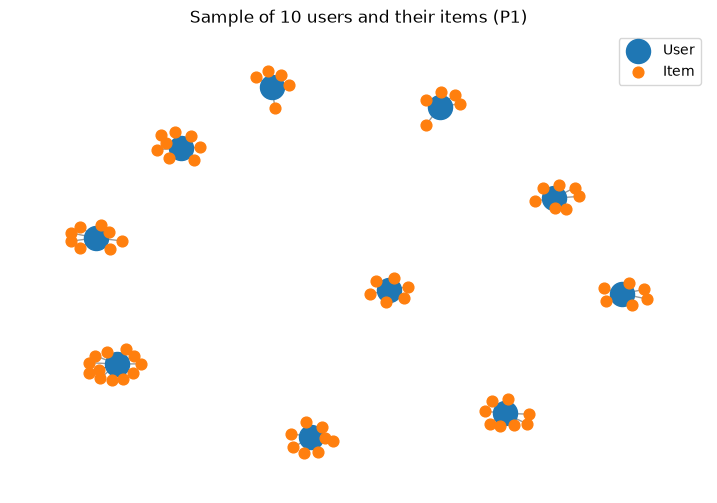

In [96]:
import networkx as nx
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
candidates = np.where((per_user >= 5) & (per_user <= 15))[0]
sample_users = rng.choice(candidates, size=10, replace=False)

G = nx.Graph()
user_nodes = []
for u in sample_users:
    name = f"U{user_ids.cat.categories[u]}"
    user_nodes.append(name)
    for i in X_user[u].indices:
        G.add_edge(name, f"I{item_ids.cat.categories[i]}")
item_nodes = [n for n in G.nodes if n not in user_nodes]

pos = nx.spring_layout(G, seed=42)
plt.figure(figsize=(9, 6))
nx.draw_networkx_nodes(G, pos, nodelist=user_nodes, node_color="tab:blue", node_size=300, label="User")
nx.draw_networkx_nodes(G, pos, nodelist=item_nodes, node_color="tab:orange", node_size=60, label="Item")
nx.draw_networkx_edges(G, pos, alpha=0.4)
plt.legend()
plt.axis("off")
plt.title("Sample of 10 users and their items (P1)")
plt.show()

The plot shows 10 randomly sampled users and the items they interacted with. The users form 10 separate clusters because none of them share an item, which illustrates how little overlap exists between users.

### **Vector Space Modelling: Item**

In [97]:
X_item = X_user.T.tocsr()

In [98]:
n_items, n_users = X_item.shape
density = X_item.nnz / (n_items * n_users)
per_item = np.diff(X_item.indptr)  # number of different users per item

print("Shape:", X_item.shape)
print("Dimension per item vector:", n_users)
print("Non-zero entries:", X_item.nnz)
print(f"Density: {density:.6%}  |  Sparsity: {1 - density:.4%}")
print(f"Users per item: mean={per_item.mean():.2f}, median={np.median(per_item):.0f}, max={per_item.max()}")
print(f"Items with only 1 user: {(per_item == 1).mean():.1%}")

Shape: (60107, 98513)
Dimension per item vector: 98513
Non-zero entries: 143668
Density: 0.002426%  |  Sparsity: 99.9976%
Users per item: mean=2.39, median=1, max=142
Items with only 1 user: 60.2%


Each item is a vector with 98,513 dimensions, one for every user, so the item-user matrix has shape 60,107 × 98,513 with the same 143,668 non-zero entries and the same sparsity of 99.9976%. Each item is seen by 2.39 users on average (median 1, maximum 142), and 60.2% of items have only one user. Items therefore have slightly more interactions per row than users, but the data is still very sparse.

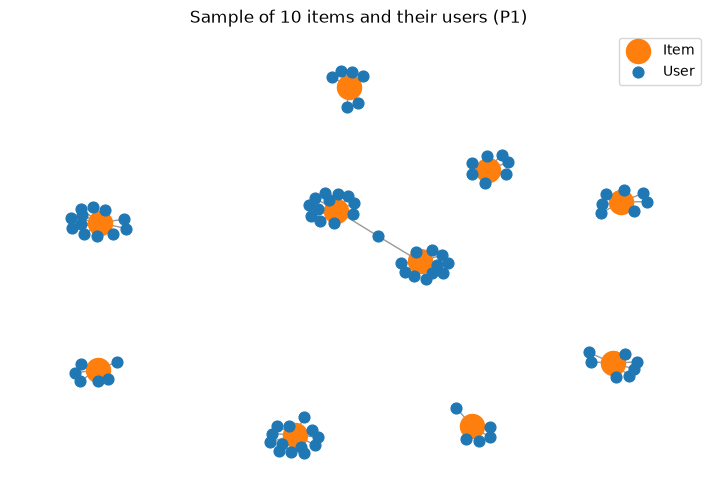

In [99]:
rng = np.random.default_rng(42)
candidates = np.where((per_item >= 5) & (per_item <= 15))[0]
sample_items = rng.choice(candidates, size=10, replace=False)

G = nx.Graph()
item_nodes = []
for i in sample_items:
    name = f"I{item_ids.cat.categories[i]}"
    item_nodes.append(name)
    for u in X_item[i].indices:
        G.add_edge(name, f"U{user_ids.cat.categories[u]}")
user_nodes = [n for n in G.nodes if n not in item_nodes]

pos = nx.spring_layout(G, seed=42)
plt.figure(figsize=(9, 6))
nx.draw_networkx_nodes(G, pos, nodelist=item_nodes, node_color="tab:orange", node_size=300, label="Item")
nx.draw_networkx_nodes(G, pos, nodelist=user_nodes, node_color="tab:blue", node_size=60, label="User")
nx.draw_networkx_edges(G, pos, alpha=0.4)
plt.legend()
plt.axis("off")
plt.title("Sample of 10 items and their users (P1)")
plt.show()

The plot shows 10 randomly sampled items and the users who interacted with them. The items form 9 clusters, because two of them are connected through a shared user. Most items still form their own isolated clusters, which confirms the sparsity of the item side.

### **Projection Comparison (User vs Item)**

In [100]:
from scipy.sparse.csgraph import connected_components

B_user = (X_user > 0).astype(np.float32).tocsr()  # 0/1 version of the matrix
B_item = B_user.T.tocsr()

def projection_stats(B, name):
    S = (B @ B.T).tocsr()          # number of shared neighbours between two rows
    S.setdiag(0)
    S.eliminate_zeros()
    n = S.shape[0]
    n_comp, labels = connected_components(S, directed=False)
    return {
        "projection": name,
        "nodes": n,
        "all possible pairs": n * (n - 1) // 2,
        "dense matrix (GB, float32)": round(n * n * 4 / 1e9, 1),
        "pairs sharing >= 1 neighbour": S.nnz // 2,
        "rows with >= 1 neighbour (%)": round((np.diff(S.indptr) > 0).mean() * 100, 1),
        "largest component (%)": round(np.bincount(labels).max() / n * 100, 1),
    }

pd.DataFrame([projection_stats(B_user, "User-User"),
              projection_stats(B_item, "Item-Item")]).set_index("projection").astype(object).T

projection,User-User,Item-Item
nodes,98513,60107
all possible pairs,4852356328,1806395671
"dense matrix (GB, float32)",38.8,14.5
pairs sharing >= 1 neighbour,551582,963747
rows with >= 1 neighbour (%),75.4,50.9
largest component (%),49.3,38.1


The User-User projection has 98,513 nodes and the Item-Item projection has 60,107, and as dense matrices they would need about 38.8 GB and 14.5 GB. Only 551,582 user pairs and 963,747 item pairs share at least one neighbour, so sparse storage keeps both cheap. The user projection reaches more rows: 75.4% of users have at least one neighbour compared with 50.9% of items, and its largest connected component holds 49.3% of users versus 38.1% of items. The User-User projection is therefore chosen, because it is more effective and matches the user-based KNN used in the Analytics part.

### **Similarity Computation**

In [101]:
from sklearn.preprocessing import normalize

X_norm = normalize(X_user)  # each row has length 1, so dot product = cosine similarity

# Reproducible reference user: 3+ items and 5+ neighbours
S = (B_user @ B_user.T).tocsr()
S.setdiag(0)
S.eliminate_zeros()
n_neighbours = np.diff(S.indptr)
per_user = np.diff(X_user.indptr)

rng = np.random.default_rng(42)
candidates = np.where((per_user >= 3) & (n_neighbours >= 5))[0]
ref = rng.choice(candidates)
ref_id = int(user_ids.cat.categories[ref])

sims = (X_norm @ X_norm[ref].T).toarray().ravel()
sims[ref] = -1  # exclude the reference itself
top5 = np.argsort(-sims, kind="stable")[:5]

top5_df = pd.DataFrame({"visitor": user_ids.cat.categories[top5],
                        "cosine": sims[top5].round(4)})
print("Reference visitor:", ref_id)
top5_df

Reference visitor: 122533


,visitor,cosine
0,188740,0.8944
1,233423,0.6325
2,328186,0.6325
3,630421,0.6325
4,1327042,0.6325


In [102]:
rows = [{"ref": ref_id, "other": int(v), "score": float(s)}
        for v, s in zip(top5_df["visitor"], top5_df["cosine"])]

write_query = """
UNWIND $rows AS row
MATCH (a:Visitor {visitorId: row.ref})
MATCH (b:Visitor {visitorId: row.other})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.execute_query(write_query, rows=rows, database_="neo4j")

In [103]:
top5_query = """
MATCH (a:Visitor {visitorId: $ref})-[s:SIMILAR_TO]->(b:Visitor)
RETURN a.visitorId AS reference, b.visitorId AS similar_visitor, s.score AS score
ORDER BY score DESC
LIMIT 5
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    records, _, _ = driver.execute_query(top5_query, ref=ref_id, database_="neo4j")
pd.DataFrame([r.data() for r in records])

,reference,similar_visitor,score
0,122533,188740,0.8944
1,122533,233423,0.6325
2,122533,1327042,0.6325
3,122533,630421,0.6325
4,122533,328186,0.6325


Cosine similarity was computed on the weighted user matrix (view = 1, add to cart = 3, bought = 5) for reference visitor 122533, selected with seed 42. The most similar visitor is 188740 with a score of 0.8944, followed by four visitors that tie at 0.6325: 233423, 328186, 630421 and 1327042. A high first score means the top neighbour has a very similar interaction pattern, while the tied scores show that the other four neighbours share a similar amount of overlap with the reference.

The five scores were written to the graph with `UNWIND`, which processes each row of the list, and `MERGE (a)-[s:SIMILAR_TO]->(b)`, which creates each relationship only once, and `SET s.score = row.score` stores the cosine value on it. The write returned `properties_set: 5` and the relationship count is 5, which confirms that all five were stored. The query `MATCH (a)-[s:SIMILAR_TO]->(b)` with `ORDER BY score DESC LIMIT 5` returns the same five visitors from the graph, and the four tied visitors appear in a different order than in Python because ties have no defined order.

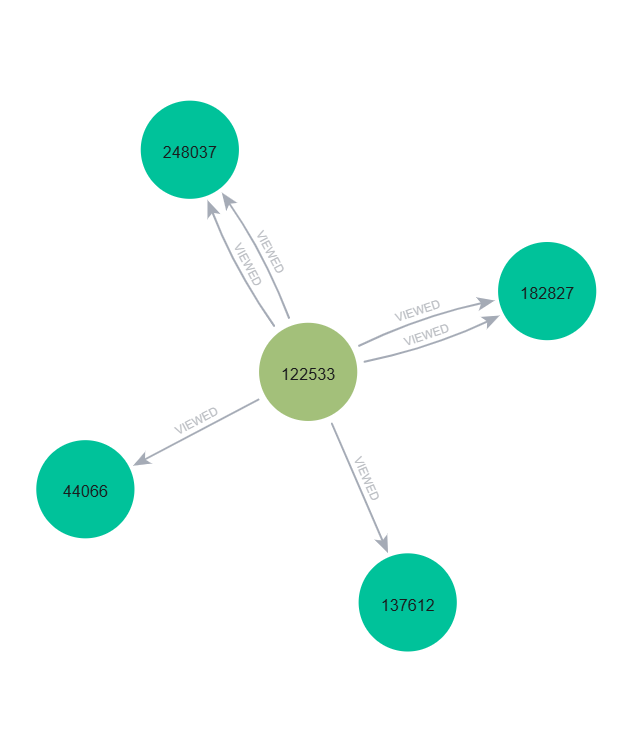

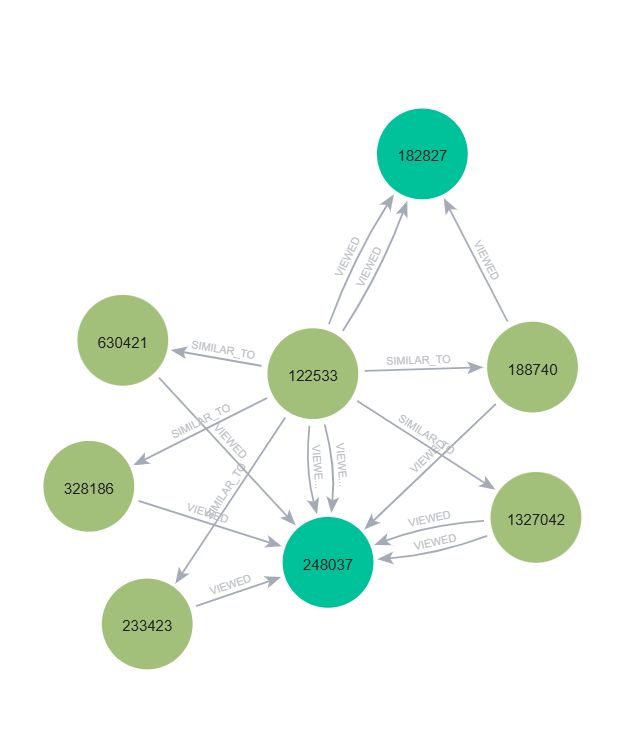

In [104]:
from IPython.display import Image, display
display(Image("before_similarity.png", width=700))
display(Image("after_similarity.png", width=700))

The picture before the similarity step was produced with this query, which shows the reference visitor and the items it interacted with:

```cypher
MATCH (v:Visitor {visitorId: 122533})-[r]->(i:Item) RETURN v, r, i
```

The picture after the similarity step was produced with this query, which also shows the five similar visitors, the `SIMILAR_TO` links and the items they share:

```cypher
MATCH (a:Visitor {visitorId: 122533})-[s:SIMILAR_TO]->(b:Visitor)
OPTIONAL MATCH (a)-[r1]->(i:Item)<-[r2]-(b)
RETURN a, s, b, i, r1, r2
```

The first picture shows reference visitor 122533 connected only to the items it interacted with, so visitors are linked only indirectly through items. The second picture shows five new `SIMILAR_TO` relationships that connect this visitor directly to its most similar visitors, each carrying a score between 0.6325 and 0.8944. The graph therefore gains direct visitor-to-visitor links on top of the existing visitor-to-item links.

## **Analytics**

### **KNN Recommendation**
The recommender uses k = 5 nearest neighbours by cosine similarity on P1. Each candidate item is scored by the similarity-weighted interaction strength of the neighbours, and items the user already knows from P1 are removed. The top 3 items of the ranking are advertised, while Hit@5 and NDCG@5 use the top 5. An item is relevant if the user added it to cart or bought it in P2 without touching it in P1, and the random user is drawn with seed 42 from users who have at least one relevant item and at least three recommendations.

In [105]:
K, N = 5, 5

def recommend(u, k=K, n=N):
    sims = (X_norm @ X_norm[u].T).toarray().ravel()
    sims[u] = -1
    nbrs = np.argsort(-sims, kind="stable")[:k]
    nbrs = nbrs[sims[nbrs] > 0]
    scores = np.asarray(X_user[nbrs].multiply(sims[nbrs][:, None]).sum(axis=0)).ravel()
    scores[X_user[u].indices] = 0           # remove items the user already knows
    top = np.argsort(-scores, kind="stable")[:n]
    top = top[scores[top] > 0]
    return nbrs, sims[nbrs], top, scores[top]

In [106]:
p2 = pd.read_csv("data/events_p2.csv")
p2 = p2[p2["event"].isin(["addtocart", "transaction"])]

user_idx = pd.Series(range(len(user_ids.cat.categories)), index=user_ids.cat.categories)
item_idx = pd.Series(range(len(item_ids.cat.categories)), index=item_ids.cat.categories)
p2 = p2[p2["visitorid"].isin(user_idx.index) & p2["itemid"].isin(item_idx.index)]

relevant = {}
for v, g in p2.groupby("visitorid"):
    u = user_idx[v]
    items = set(item_idx[g["itemid"].unique()]) - set(X_user[u].indices)
    if items:
        relevant[u] = items

eligible = np.array(sorted(u for u in relevant if len(recommend(u)[2]) >= 3))
print("Eligible users:", len(eligible))

rng = np.random.default_rng(42)
u = int(rng.choice(eligible))
nbrs, nsims, top, tscores = recommend(u)

print("Random user:", user_ids.cat.categories[u])
print(pd.DataFrame({"neighbour": user_ids.cat.categories[nbrs], "similarity": nsims.round(4)}))

Eligible users: 35
Random user: 101175
   neighbour  similarity
0      23184      0.4714
1      36526      0.4714
2    1106383      0.4714
3     348147      0.3018
4     806973      0.2357


There are 35 eligible users, meaning users with at least one new relevant item in P2 and at least three recommended items, and seed 42 selected user 101175. Its five nearest neighbours are 23184, 36526 and 1106383 (similarity 0.4714 each), 348147 (0.3018) and 806973 (0.2357). The similarity values are moderate, so the neighbours resemble the user only partly.

In [107]:
ads = pd.DataFrame({"rank": range(1, 6)[:len(top)],
                    "item": item_ids.cat.categories[top],
                    "score": tscores.round(3)})
print("Top 5 ranking:")
display(ads)
print("Advertised items (top 3):", list(ads["item"][:3]))

Top 5 ranking:


,rank,item,score
0,1,204209,1.207
1,2,335331,1.207
2,3,15320,0.302
3,4,91676,0.302
4,5,156418,0.302


Advertised items (top 3): [204209, 335331, 15320]


The neighbours' items were scored by similarity-weighted interaction strength, after removing items the user already knew. The top 5 ranking is 204209 and 335331 (1.207 each), followed by 15320, 91676 and 156418 (0.302 each). The three advertised items for k = 5 are therefore 204209, 335331 and 15320, and the last three ranks are tied in score.

In [108]:
def hit_at_n(rec, rel, n=N):
    return int(any(i in rel for i in rec[:n]))

def ndcg_at_n(rec, rel, n=N):
    dcg = sum(1 / np.log2(r + 2) for r, i in enumerate(rec[:n]) if i in rel)
    idcg = sum(1 / np.log2(r + 2) for r in range(min(n, len(rel))))
    return dcg / idcg

rel = relevant[u]
print("Relevant items in P2:", sorted(item_ids.cat.categories[list(rel)]))
print("Hit@5 :", hit_at_n(top, rel))
print("NDCG@5:", round(ndcg_at_n(top, rel), 4))

# Extra: average over all eligible users
h = [hit_at_n(recommend(x)[2], relevant[x]) for x in eligible]
nd = [ndcg_at_n(recommend(x)[2], relevant[x]) for x in eligible]
print(f"All {len(eligible)} eligible users: Hit@5 = {np.mean(h):.4f}, NDCG@5 = {np.mean(nd):.4f}")

Relevant items in P2: [91086, 98374, 234215, 276240, 285637, 288887, 415020, 446102]
Hit@5 : 0
NDCG@5: 0.0
All 35 eligible users: Hit@5 = 0.0000, NDCG@5 = 0.0000


User 101175 has 8 relevant items in P2 (91086, 98374, 234215, 276240, 285637, 288887, 415020 and 446102), and none of them appear in the top 5. This gives Hit@5 = 0 and NDCG@5 = 0.0 for this user. The average over all 35 eligible users is also 0.0000 for both metrics, so no eligible user received a correct recommendation. This is a valid result rather than a code error: 81.6% of users have only one item in P1, so their neighbours share very little with them, and the KNN has little signal to predict purchases in the test period.